In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

Week 4 Capstone — Predicting Internship Selection Outcomes

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving applicants_cleaned.csv to applicants_cleaned.csv


In [ ]:
df = pd.read_csv('applicants_cleaned.csv')
np.random.seed(42)
df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))
df['has_portfolio'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.4, 0.6])
df['prior_hackathon_participation'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.3, 0.7])
df['statement_quality_score'] = np.random.randint(1, 11, size=len(df))

In [ ]:
# Convert Yes/no to 0/1
df['has_portfolio'] = df['has_portfolio'].map({'Yes': 1, 'No': 0})
df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({'Yes': 1, 'No': 0})


In [ ]:
#Convert the target column (what you're predicting) to 0/1
df['target'] = df['Status'].apply(lambda x: 1 if x == 'Selected' else 0)
df_model = df[df['Status'] != 'Under Review'].copy()

In [ ]:
#One-hot encode the Domain column
df_model = pd.get_dummies(df_model, columns=['Domain Applied'], drop_first=True)

In [ ]:
# Select your final feature set
feature_columns = ['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation',
'statement_quality_score'] + [col for col in df_model.columns if col.startswith('Domain Applied_')]
X = df_model[feature_columns]
y = df_model['target']

Applicant Name, Email and Phone are excluded because they are personal identifiers rather than meaningful measures of applicant suitability. University and Application Date are also excluded from the initial model because they are not among the selected predictors

In [ ]:
# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42)

In [ ]:
# Train the Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Evaluate the Model — Honestly

In [ ]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 60.00%


Precision: 50.00%
Recall: 75.00%


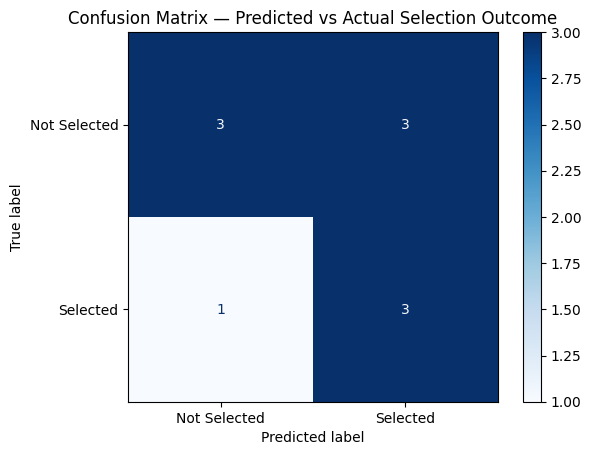

In [ ]:
# Precision, Recall, and/or Confusion Matrix
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Selected', 'Selected'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix — Predicted vs Actual Selection Outcome')
plt.show()

### Model Evaluation and Interpretation

**Precision: 50%**

Of all the applicants the model predicted would be Selected, 50% were actually Selected. This means that half of its positive predictions were correct.

**Recall: 75%**

Of all the applicants who were actually Selected, the model correctly identified 75% (3 out of 4 applicants). It missed only one selected applicant.

**Confusion Matrix**

The confusion matrix shows that:
- True Positives: 3 applicants were correctly predicted as Selected.
- True Negatives: 3 applicants were correctly predicted as Not Selected.
- False Positives: 3 applicants were incorrectly predicted as Selected.
- False Negatives: 1 applicant was incorrectly predicted as Not Selected.

**Overall Interpretation**

The model correctly classified 6 out of 10 applicants, resulting in an accuracy of 60%. Although it was relatively successful at identifying selected applicants, its precision indicates that it still made several incorrect positive predictions.

## Model Limitations

Although the model demonstrates how machine learning can help predict internship selection outcomes, it has some limitations:

1. **Small and Simulated Dataset:** The dataset is relatively small, and four features were simulated rather than collected from real applications. This means they may not accurately reflect actual applicants.

2. **Limited Test Data:** Since the test set is small, the results could change if the data were split differently. Therefore, the results are illustrative and not a guarantee of how the model would perform in practice.

3. **Potential Bias:** The model could learn and repeat biases from previous selection decisions. For example, it might favour certain universities even when this does not reflect an applicant's actual abilities.

4. **Human Oversight:** The model should support decision-making, not replace human judgement. Final selection decisions should still involve human review to ensure applicants are assessed fairly.

**Overall:** The model is useful for demonstrating machine learning, but it would need more real applicant data, further testing and fairness checks before it could be considered reliable for actual internship selection.

In [ ]:
# Interpret — Which Features Mattered Most?
coefficients = pd.DataFrame({
'Feature': X.columns,
'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)
print(coefficients)

                                 Feature  Coefficient
2          prior_hackathon_participation     0.507118
0                      num_skills_listed     0.195330
6            Domain Applied_UI/UX Design    -0.026542
3                statement_quality_score    -0.110942
7         Domain Applied_Web Development    -0.132456
5  Domain Applied_Mobile App Development    -0.264578
4            Domain Applied_Data Science    -0.676120
1                          has_portfolio    -0.968179


The coefficients show how each feature is associated with the model's prediction of an applicant being Selected.

- **Prior hackathon participation** had the strongest positive coefficient (0.507), suggesting that applicants with previous hackathon participation were more likely to be predicted as Selected.
- **Number of skills listed** also had a positive coefficient (0.195), indicating a positive association with the prediction of Selection.
- **Having a portfolio** had the strongest negative coefficient (-0.968), suggesting a negative association with the prediction of Selection.
- **Data Science** also had a relatively strong negative coefficient (-0.676).
- The remaining features had smaller negative coefficients.

**Overall:** Prior hackathon participation and the number of skills listed were positively associated with predicted selection, while having a portfolio and applying for Data Science had relatively strong negative associations in this model.

## Executive Summary

**What we did:** We built a simple prediction model using NextGenLearners applicant records to explore which factors are associated with applicants being selected for the internship programme.

**What we found:** The model correctly predicted 60% of the selection outcomes in its test group. It correctly identified 75% of the applicants who were actually selected, although only 50% of its predictions of selection were correct. Previous hackathon participation and the number of skills listed had positive associations with predicted selection. Having a portfolio and applying for Data Science had negative associations in this model.

**Important caveats:** This analysis used a small dataset, and several features, including the number of skills listed, previous hackathon participation and statement quality, were artificially generated for this exercise rather than collected from real historical applications. The test group also contained only 10 applicants, meaning the results may change with a different dataset or test group. Before using a model like this in real selection decisions, NextGenLearners would need to collect consistent information from actual applications and test the model using a much larger dataset. The model should support reviewers rather than replace human judgement, particularly because it may repeat unfair patterns in previous selection decisions.

**Recommendation:** NextGenLearners should prioritise collecting accurate and consistent applicant information from future applications. This would allow the programme to evaluate whether factors such as skills, previous hackathon participation and written statements genuinely relate to successful selection outcomes before considering the use of prediction models in the selection process.